In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [2]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp



In [4]:
solver = RE.solver0D()
solver.display() # Show default values

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


In [14]:
solver.R0 = 2.96
solver.a = 1.25
solver.k = 1
solver.ni = 1e19
solver.Btor = 2.8

solver.I0 = 6.17e6
solver.Ir0 = 0
solver.T0 = 4e3
solver.Tf = 7.5

solver.n_imp = solver.ni / 10
solver.Z_imp = 6
solver.A_imp = 12
solver.tmax = 100e-3
solver.display()

Major radius R0 [m] = 2.960
Minor radius a [m] = 1.250
Elongation k [-] = 1.000
ni [per cubic m] = 1e+19
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 2.8
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 6.17e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 4e+03
Final Temp. Tf [eV] = 7.5
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e+18
Added Impurity Z, A [-] = 6, 12

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


In [15]:
t, Ip, Ir, Wk = solver.solve()


<>:82: SyntaxWarning: invalid escape sequence '\p'
<>:84: SyntaxWarning: invalid escape sequence '\p'
<>:94: SyntaxWarning: invalid escape sequence '\g'
<>:82: SyntaxWarning: invalid escape sequence '\p'
<>:84: SyntaxWarning: invalid escape sequence '\p'
<>:94: SyntaxWarning: invalid escape sequence '\g'
C:\Users\grace\AppData\Local\Temp\ipykernel_3412\4082951961.py:82: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
C:\Users\grace\AppData\Local\Temp\ipykernel_3412\4082951961.py:84: SyntaxWarning: invalid escape sequence '\p'
  axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
C:\Users\grace\AppData\Local\Temp\ipykernel_3412\4082951961.py:94: SyntaxWarning: invalid escape sequence '\g'
  axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')


final current:  6.00316053100587


C:\Users\grace\AppData\Local\Temp\ipykernel_3412\4082951961.py:103: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2,1].legend()


Text(0.5, 56.08333333333332, 't [ms]')

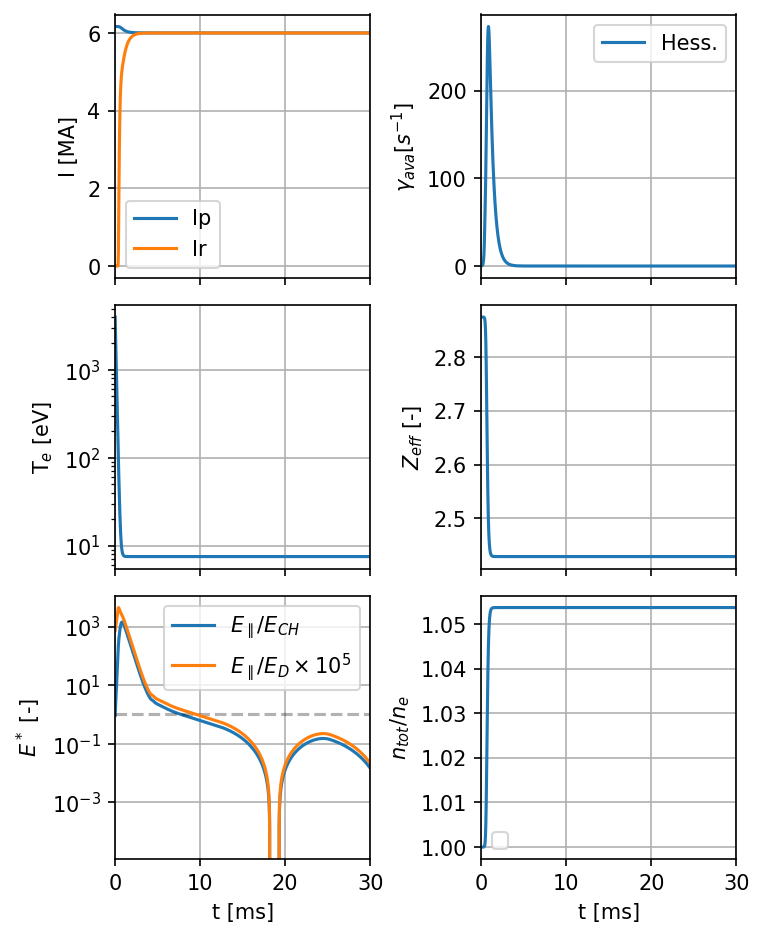

In [16]:
print('final current: ', Ip[-1]/1e6)


# Calculate other relvant quantities
T = solver.getTemp(t)
Zion = solver.getImpurityIonization(T)
ne, ntot = solver.getElecDensity(Zion)
Zeff = (solver.ni + solver.nD  + solver.n_imp * Zion**2) / ne
lnA = getCoulombLog(ne, T)
eta = (0.51* getTransSpitzerResistivity(lnA, T, Zeff)* 0.01)
Epar = eta * (Ip - Ir) / (np.pi * solver.a**2 * solver.k)
Ec = getConnorHastieField(ne, lnA)
Ed = getDreicerField(ne, lnA, T)
E_star = Epar / Ec
Wc = getCriticalRunawayEnergy(E_star) / const.eV


# Primary Sources
if solver.iDreicer == 1:
    SD = getDreicerSource(
        E_star, ne, lnA, Zeff, T)

elif solver.iDreicer == 2:
    SD = getDreicerRateHesslow(
        solver.ni,
        solver.n_imp,
        solver.Z_imp,
        Zion,
        Epar/Ed,
        T)
else:
    SD = np.zeros_like(E_star)

if solver.iTritium:
    ST = getTritBetaDecay(
        0.5*solver.ni,
        E_star)
else:
    ST = np.zeros_like(E_star)


if solver.iCompton:
    SC = getComptonSource(
        E_star,
        ntot,
        'ARC-P')
    mask = T < 2.6e3
    SC[mask] = getComptonSource(
        E_star[mask],
        ntot,
        'ARC-NP')
else:
    SC = np.zeros_like(E_star)

# Secondary Sources
#Yav_RP =  1 * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
Yav_Hess = np.zeros_like(t)

for i in range(len(t)):
    Yav_Hess[i] = solver.getAvalancheRates(
        E_star[i],
        ntot,
        ne[i],
        T[i],
        lnA[i],
        Zeff[i],
        Zion[i]
    )

############ Plot ##################
fig, axs = plt.subplots(3,2,sharex=True,figsize=(5,6),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()

axs[1,0].plot(t*1e3,T)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav_Hess,label='Hess.')
#axs[0,1].plot(t*1e3,Yav_RP,label='RP')
#axs[0,1].plot(t*1e3,Yav_RP*(ntot/ne),label='RP$\\times n_{tot}/n_e$')
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
# axs[0,1].set_yscale('log')
axs[0,1].legend()

axs[1,1].plot(t*1e3,Zeff)
axs[1,1].set_ylabel('$Z_{eff}$ [-]')

axs[2,1].plot(t*1e3,ntot/ne)
axs[2,1].set_ylabel('$n_{tot}/n_e$')
axs[2,1].legend()


fig.tight_layout(pad=0.5)
for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,30])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

In [ ]:
solver.Z_imp = 10
solver.A_imp = 20
solver.n_imp = 1e20
solver.Tf = 10
solver.T0 = 20e3
solver.nD = 2 * solver.n_imp
solver.iDreicer = 0
solver.tmax = 15e-3
solver.Ir0 = 10000
solver.k = 1
solver.R

t, Ip, Ir, Wk = solver.solve()